# Prograf vs. Envarsus XR: Comparative Pharmacovigilance Analysis Using FAERS and Python

## Project overview

This notebook compares adverse event reports for two tacrolimus formulations, **Prograf** (immediate release) and **Envarsus XR** (extended release), using the FDA Adverse Event Reporting System (FAERS) through the openFDA Drug Event API.

**Scope**
- Reports received between **1 January and 31 December 2025**.
- Either formulation classified as the **Primary Suspect** drug (`drugcharacterization = 1`).
- Reported indication: **Renal transplant**.

**Objective**
- Evaluate whether tacrolimus formulation was associated with the seriousness of reported adverse events (Serious vs. Non-serious).
- Describe demographics, serious outcomes, and the most frequently reported reactions (MedDRA Preferred Terms) for each formulation.

**Notebook structure**

| Module | Content |
|---|---|
| 1. Data acquisition | openFDA queries and local raw-data snapshot |
| 2. Data preparation | Deduplication, Primary Suspect and indication filters, cohort construction |
| 3. Descriptive analysis | Seriousness, demographics, serious outcomes, top reactions |
| 4. Statistical analysis | Fisher's exact test, odds ratio with exact 95% CI, forest plot, Phi |
| 5. Export | Tables saved to `results/tables/` (plots are saved to `results/plots/` as they are created) |

> **Important:** FAERS is a spontaneous reporting system. It has no exposure denominator, so the percentages in this notebook describe the **proportion of reports**, not incidence or risk, and do not establish causality.

In [1]:
# -------------------------------------------------------------
# SETUP. Libraries
# -------------------------------------------------------------
import json
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import scipy
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

print(f"pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"SciPy: {scipy.__version__}")
print(f"Matplotlib: {plt.matplotlib.__version__}")
print(f"seaborn: {sns.__version__}")
print(f"requests: {requests.__version__}")

pandas: 3.1.1
NumPy: 2.5.4
SciPy: 1.18.1
Matplotlib: 3.11.2
seaborn: 0.13.2
requests: 2.34.2


## Module 1. Data acquisition

Data are retrieved from the openFDA Drug Event endpoint without an API key (limits: 240 requests per minute and 1,000 requests per day per IP address). Each request returns at most 1,000 records (`limit`); this analysis uses `limit = 999`.

To make the analysis reproducible, the raw JSON response is saved locally with its retrieval date the first time it is downloaded. Every later run loads that snapshot instead of querying the API, because FAERS is updated quarterly and new downloads may return different counts.

In [2]:
# -------------------------------------------------------------
# MODULE 1. DATA ACQUISITION
# Step 1.1. Test the connection to the openFDA FAERS endpoint
# -------------------------------------------------------------

# 1. Define the FAERS endpoint
url = "https://api.fda.gov/drug/event.json"

# 2. Request only 5 reports to test the connection
response = requests.get(url, params={"limit": 5})

# 3. Check the response status (expected: 200 = OK)
print(response.status_code)

200


In [3]:
# -------------------------------------------------------------
# MODULE 1. DATA ACQUISITION
# Step 1.2. Define project folders
# -------------------------------------------------------------

# 1. Folders relative to the notebook (notebooks/)
raw_dir = Path("../data/raw")          # raw openFDA snapshots
plots_dir = Path("../results/plots")   # exported figures
tables_dir = Path("../results/tables") # exported tables

# 2. Create the folders if they do not exist
for folder in [raw_dir, plots_dir, tables_dir]:
    folder.mkdir(parents=True, exist_ok=True)

print("Raw data folder:", raw_dir.resolve())

Raw data folder: D:\mane\pandas-learning-mane\faers-prograf-envarsus\data\raw


In [4]:
# -------------------------------------------------------------
# MODULE 1. DATA ACQUISITION
# Step 1.3. Load (or download) Prograf candidate reports, 2025
# -------------------------------------------------------------

# 1. Path of the local snapshot
prograf_file = raw_dir / "prograf_2025_raw.json"

# 2. Load the snapshot if it exists; otherwise download it and save it with its retrieval date
if prograf_file.exists():
    with open(prograf_file, encoding="utf-8") as f:
        data_prograf_2025 = json.load(f)
    print("Loaded from file. Retrieved on:", data_prograf_2025["retrieved_on"])
else:
    params = {
        "search": (
            'patient.drug.medicinalproduct:"PROGRAF" AND '
            'receivedate:[20250101 TO 20251231]'
        ),
        "limit": 999
    }
    response = requests.get(url, params=params)
    print(response.status_code)

    data_prograf_2025 = response.json()
    data_prograf_2025["retrieved_on"] = date.today().isoformat()

    with open(prograf_file, "w", encoding="utf-8") as f:
        json.dump(data_prograf_2025, f)
    print("Downloaded and saved:", prograf_file.name)

# 3. Extract the list of reports
prograf_reports = data_prograf_2025["results"]

# 4. Check that all available reports were retrieved
downloaded = len(prograf_reports)
total = data_prograf_2025["meta"]["results"]["total"]
print("Reports retrieved:", downloaded)
print("Total matches in openFDA:", total)

if downloaded < total:
    print("WARNING: more reports than the per-request limit; pagination with 'skip' is required.")

Loaded from file. Retrieved on: 2026-11-16
Reports retrieved: 692
Total matches in openFDA: 692


In [5]:
# -------------------------------------------------------------
# MODULE 1. DATA ACQUISITION
# Step 1.4. Load (or download) Envarsus candidate reports, 2025
# -------------------------------------------------------------

# 1. Path of the local snapshot
envarsus_file = raw_dir / "envarsus_2025_raw.json"

# 2. Load the snapshot if it exists; otherwise download it and save it with its retrieval date
if envarsus_file.exists():
    with open(envarsus_file, encoding="utf-8") as f:
        data_envarsus_2025 = json.load(f)
    print("Loaded from file. Retrieved on:", data_envarsus_2025["retrieved_on"])
else:
    params = {
        "search": (
            'patient.drug.medicinalproduct:"ENVARSUS" AND '
            'receivedate:[20250101 TO 20251231]'
        ),
        "limit": 999
    }
    response = requests.get(url, params=params)
    print(response.status_code)

    data_envarsus_2025 = response.json()
    data_envarsus_2025["retrieved_on"] = date.today().isoformat()

    with open(envarsus_file, "w", encoding="utf-8") as f:
        json.dump(data_envarsus_2025, f)
    print("Downloaded and saved:", envarsus_file.name)

# 3. Extract the list of reports
envarsus_reports = data_envarsus_2025["results"]

# 4. Check that all available reports were retrieved
downloaded = len(envarsus_reports)
total = data_envarsus_2025["meta"]["results"]["total"]
print("Reports retrieved:", downloaded)
print("Total matches in openFDA:", total)

if downloaded < total:
    print("WARNING: more reports than the per-request limit; pagination with 'skip' is required.")

Loaded from file. Retrieved on: 2026-11-16
Reports retrieved: 387
Total matches in openFDA: 387


## Module 2. Data preparation

The analytical cohort is built in five stages: combine both queries and keep the latest version of each report, expand the drugs listed in each report, keep Prograf or Envarsus XR as Primary Suspect, keep the renal transplant indication, and exclude reports that mention both formulations.

In [6]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.1. Convert JSON reports to DataFrames
# -------------------------------------------------------------

# prograf_reports and envarsus_reports are lists of dictionaries (one per report)

# 1. Flatten each list into a DataFrame
df_prograf = pd.json_normalize(prograf_reports)
df_envarsus = pd.json_normalize(envarsus_reports)

# 2. Check dimensions
print("Prograf:", df_prograf.shape)
print("Envarsus:", df_envarsus.shape)

Prograf: (692, 40)
Envarsus: (387, 40)


In [7]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.2. Identify control fields
# -------------------------------------------------------------

# 1. Find columns related to identifiers or versions (case-insensitive regex; | means OR)
control_fields = df_prograf.columns[
    df_prograf.columns.str.contains("case|primary|safetyreport|version", case=False, regex=True)
]

# 2. Show the fields found
print(control_fields.tolist())

['safetyreportversion', 'safetyreportid', 'primarysourcecountry', 'primarysource.reportercountry', 'primarysource.qualification', 'primarysource.literaturereference']


In [8]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.3. Review report identifiers and versions
# -------------------------------------------------------------

print("PROGRAF")
print(df_prograf[["safetyreportid", "safetyreportversion"]].head().to_string(index=False))

print("\nENVARSUS")
print(df_envarsus[["safetyreportid", "safetyreportversion"]].head().to_string(index=False))

PROGRAF
safetyreportid safetyreportversion
      24795627                   1
      24796871                   1
      24797335                   1
      24798706                   1
      24798707                   1

ENVARSUS
safetyreportid safetyreportversion
      24797981                   2
      24799593                   1
      24802889                   1
      24805872                   1
      24809154                   1


In [9]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.4. Combine candidate reports and keep the latest version
# -------------------------------------------------------------

# 1. Combine both DataFrames
df_candidates = pd.concat([df_prograf, df_envarsus], ignore_index=True)

# 2. Sort by version (most recent first) so the latest version of each report is kept
df_candidates["safetyreportversion"] = pd.to_numeric(df_candidates["safetyreportversion"])
df_candidates = df_candidates.sort_values("safetyreportversion", ascending=False)

# 3. Keep one record per report
df_candidates = df_candidates.drop_duplicates(subset="safetyreportid").copy()

print("Unique candidate reports:", len(df_candidates))

Unique candidate reports: 1072


In [10]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.5. Expand drugs per report
# -------------------------------------------------------------

# 1. Select the report identifier and its list of drugs
df_drugs = df_candidates[["safetyreportid", "patient.drug"]].copy()

# 2. One row per drug
df_drugs = df_drugs.explode("patient.drug").reset_index(drop=True)

# 3. Expand each drug dictionary into columns
drug_details = pd.json_normalize(df_drugs["patient.drug"])

# 4. Combine the identifier with the drug fields
df_drugs = pd.concat([df_drugs[["safetyreportid"]], drug_details], axis=1)

# 5. Show results
print("Dimensions:", df_drugs.shape)
print("\nColumns:")
print(df_drugs.columns.tolist())
print("\nFirst records:")
print(df_drugs[["safetyreportid", "medicinalproduct", "drugcharacterization", "drugindication"]].head().to_string(index=False))

Dimensions: (11609, 45)

Columns:
['safetyreportid', 'drugcharacterization', 'medicinalproduct', 'drugauthorizationnumb', 'drugstructuredosagenumb', 'drugstructuredosageunit', 'drugdosageform', 'drugadministrationroute', 'drugindication', 'drugstartdateformat', 'drugstartdate', 'drugenddateformat', 'drugenddate', 'drugtreatmentduration', 'drugtreatmentdurationunit', 'actiondrug', 'drugadditional', 'activesubstance.activesubstancename', 'openfda.application_number', 'openfda.brand_name', 'openfda.generic_name', 'openfda.manufacturer_name', 'openfda.product_ndc', 'openfda.product_type', 'openfda.route', 'openfda.substance_name', 'openfda.rxcui', 'openfda.spl_id', 'openfda.spl_set_id', 'openfda.package_ndc', 'openfda.nui', 'openfda.pharm_class_epc', 'openfda.pharm_class_moa', 'openfda.unii', 'drugseparatedosagenumb', 'drugintervaldosageunitnumb', 'drugintervaldosagedefinition', 'drugdosagetext', 'openfda.pharm_class_pe', 'openfda.pharm_class_cs', 'drugrecurreadministration', 'drugcumulati

In [11]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.6. Keep Prograf and Envarsus XR as Primary Suspect (PS)
# -------------------------------------------------------------

# 1. Identify Prograf and Envarsus, including name variants
target_drugs = df_drugs["medicinalproduct"].str.upper().str.contains(
    r"\b(?:PROGRAF|ENVARSUS)\b", regex=True, na=False
)

# 2. Identify Primary Suspect drugs (drugcharacterization = "1")
primary_suspect = df_drugs["drugcharacterization"] == "1"

# 3. Keep rows where both conditions are True
df_ps = df_drugs.loc[target_drugs & primary_suspect].copy()

# 4. Show results
print("Dimensions:", df_ps.shape)
print("\nDrugs identified:")
print(df_ps["medicinalproduct"].value_counts())

Dimensions: (958, 45)

Drugs identified:
medicinalproduct
PROGRAF        583
ENVARSUS XR    375
Name: count, dtype: int64


In [12]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.7. Keep the renal transplant indication
# -------------------------------------------------------------

# 1. Filter PS records with the renal transplant indication
df_renal = df_ps.loc[df_ps["drugindication"] == "Renal transplant"].copy()

# 2. Show results
print("Dimensions:", df_renal.shape)
print("\nDrugs:")
print(df_renal["medicinalproduct"].value_counts())

Dimensions: (187, 45)

Drugs:
medicinalproduct
ENVARSUS XR    116
PROGRAF         71
Name: count, dtype: int64


In [ ]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.8. Keep unique report-drug pairs
# -------------------------------------------------------------

# 1. A drug can appear more than once in the same report; keep one row per report-drug pair
df_report_drugs = df_renal[["safetyreportid", "medicinalproduct"]].drop_duplicates()

# 2. Show results
print("Unique report-drug pairs:", len(df_report_drugs))
print(df_report_drugs.sample(5, random_state=42).to_string(index=False))  #random_state for reproducibility

Unique report-drug pairs: 175
safetyreportid medicinalproduct
      24877336          PROGRAF
      25840643      ENVARSUS XR
      25045500      ENVARSUS XR
      25597791      ENVARSUS XR
      24963677          PROGRAF


In [14]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.9. Group drugs by report
# -------------------------------------------------------------

# 1. For each report: number of distinct target drugs and their names
df_report_class = df_report_drugs.groupby("safetyreportid").agg(
    n_drugs=("medicinalproduct", "nunique"),  # distinct target drugs in the report
    drugs=("medicinalproduct", list)          # list of those drugs
).reset_index()

# 2. Show results
print("Dimensions:", df_report_class.shape)
print("\nFirst records:")
print(df_report_class.head().to_string(index=False))

Dimensions: (174, 3)

First records:
safetyreportid  n_drugs         drugs
      24802889        1 [ENVARSUS XR]
      24810077        1 [ENVARSUS XR]
      24813954        1 [ENVARSUS XR]
      24816155        1 [ENVARSUS XR]
      24818507        1 [ENVARSUS XR]


In [15]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.10. Check for mixed exposure (both formulations)
# -------------------------------------------------------------

# 1. Distribution of the number of target drugs per report
print(df_report_class["n_drugs"].value_counts())

# 2. Reports that mention both formulations
print("\nReports with mixed exposure:")
print(df_report_class.loc[df_report_class["n_drugs"] > 1])

n_drugs
1    173
2      1
Name: count, dtype: int64

Reports with mixed exposure:
    safetyreportid  n_drugs                   drugs
121       25902670        2  [ENVARSUS XR, PROGRAF]


In [16]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.11. Classify the formulation of each report
# -------------------------------------------------------------

# 1. Label reports with both drugs as "Mixed exposure"; otherwise use the single drug name
df_report_class["formulation"] = np.where(
    df_report_class["n_drugs"] == 2,
    "Mixed exposure",
    df_report_class["drugs"].str[0]
)

# 2. Show distribution
print(df_report_class["formulation"].value_counts())

formulation
ENVARSUS XR       111
PROGRAF            62
Mixed exposure      1
Name: count, dtype: int64


In [17]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.12. Build the analytical cohort (excluding mixed exposure)
# -------------------------------------------------------------

# 1. Keep reports with only Prograf or only Envarsus XR
df_cohort = df_report_class.loc[df_report_class["formulation"] != "Mixed exposure"].copy()

# 2. Show results
print("Dimensions:", df_cohort.shape)
print("\nDistribution by formulation:")
print(df_cohort["formulation"].value_counts())

Dimensions: (173, 4)

Distribution by formulation:
formulation
ENVARSUS XR    111
PROGRAF         62
Name: count, dtype: int64


In [18]:
# -------------------------------------------------------------
# MODULE 2. DATA PREPARATION
# Step 2.13. Cohort quality checks
# -------------------------------------------------------------

print("SHAPE")
print(f"Rows: {df_cohort.shape[0]}, Columns: {df_cohort.shape[1]}")

print("\nDTYPES")
print(df_cohort.dtypes)

print("\nMISSING VALUES")
print(df_cohort.isna().sum())

print("\nUNIQUE REPORTS")
print(df_cohort["safetyreportid"].nunique())

SHAPE
Rows: 173, Columns: 4

DTYPES
safetyreportid       str
n_drugs            int64
drugs             object
formulation          str
dtype: object

MISSING VALUES
safetyreportid    0
n_drugs           0
drugs             0
formulation       0
dtype: int64

UNIQUE REPORTS
173


### Cohort construction summary

| Stage | Reports |
|---|---|
| Prograf query (2025) | 692 |
| Envarsus query (2025) | 387 |
| Unique candidate reports (latest version kept) | 1,072 |
| Prograf or Envarsus XR as PS with *Renal transplant* indication | 174 |
| Excluded: mixed exposure (both formulations) | 1 |
| **Analytical cohort** | **173** (Envarsus XR: 111; Prograf: 62) |

## Module 3. Descriptive analysis

In [19]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.1. Add the seriousness variable
# -------------------------------------------------------------

# 1. Select the report identifier and the seriousness field
df_serious = df_candidates[["safetyreportid", "serious"]].copy()

# 2. Add seriousness to the cohort
df_analysis = pd.merge(df_cohort, df_serious, on="safetyreportid", how="left")

# 3. Show results
print("Dimensions:", df_analysis.shape)
print("\nFirst records:")
print(df_analysis.head().to_string(index=False))
print("\nSeriousness distribution:")
print(df_analysis["serious"].value_counts(dropna=False))
print("\nMissing values:")
print(df_analysis.isna().sum())

Dimensions: (173, 5)

First records:
safetyreportid  n_drugs         drugs formulation serious
      24802889        1 [ENVARSUS XR] ENVARSUS XR       1
      24810077        1 [ENVARSUS XR] ENVARSUS XR       1
      24813954        1 [ENVARSUS XR] ENVARSUS XR       1
      24816155        1 [ENVARSUS XR] ENVARSUS XR       1
      24818507        1 [ENVARSUS XR] ENVARSUS XR       1

Seriousness distribution:
serious
1    165
2      8
Name: count, dtype: int64

Missing values:
safetyreportid    0
n_drugs           0
drugs             0
formulation       0
serious           0
dtype: int64


In [20]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.2. Label the seriousness variable
# -------------------------------------------------------------

# 1. openFDA codes: 1 = Serious (at least one seriousness criterion), 2 = Non-serious
df_analysis["seriousness"] = df_analysis["serious"].map({"1": "Serious", "2": "Non-serious"})

# 2. Show distribution
print(df_analysis["seriousness"].value_counts(dropna=False))

seriousness
Serious        165
Non-serious      8
Name: count, dtype: int64


In [21]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.3. Seriousness by formulation (counts)
# -------------------------------------------------------------

# A contingency table cross-tabulates two categorical variables and counts each combination

# 1. Formulation vs. seriousness
seriousness_table = pd.crosstab(df_analysis["formulation"], df_analysis["seriousness"])

print(seriousness_table)

seriousness  Non-serious  Serious
formulation                      
ENVARSUS XR            7      104
PROGRAF                1       61


In [22]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.4. Seriousness by formulation (percentages)
# -------------------------------------------------------------

# normalize="index" computes each category's proportion within its row (formulation)

# 1. Row percentages
seriousness_percent = (
    pd.crosstab(df_analysis["formulation"], df_analysis["seriousness"], normalize="index") * 100
).round(2)

print(seriousness_percent)

seriousness  Non-serious  Serious
formulation                      
ENVARSUS XR         6.31    93.69
PROGRAF             1.61    98.39


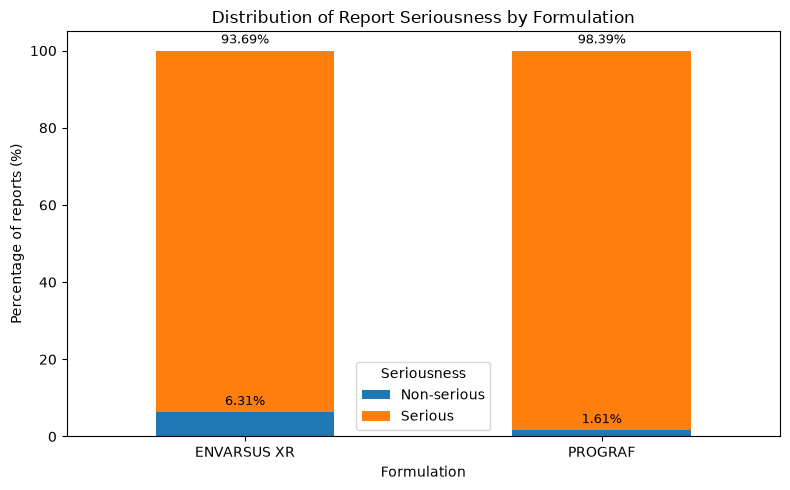

In [23]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.5. Plot: seriousness by formulation
# -------------------------------------------------------------

# 1. Stacked bar chart
ax = seriousness_percent.plot(kind="bar", stacked=True, figsize=(8, 5))

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=9)

# 2. Labels and title
plt.title("Distribution of Report Seriousness by Formulation")
plt.xlabel("Formulation")
plt.ylabel("Percentage of reports (%)")
plt.xticks(rotation=0)
plt.legend(title="Seriousness")
plt.tight_layout()

# 3. Save and show
plt.savefig(plots_dir / "01_seriousness_by_formulation.png", dpi=300, bbox_inches="tight")
plt.show()

In [24]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.6. Add demographic variables
# -------------------------------------------------------------

# 1. Select age, age unit and sex
df_demographics = df_candidates[
    ["safetyreportid", "patient.patientonsetage", "patient.patientonsetageunit", "patient.patientsex"]
].copy()

# 2. Add them to the analysis DataFrame
df_analysis = pd.merge(df_analysis, df_demographics, on="safetyreportid", how="left")

# 3. Show results
print("Dimensions:", df_analysis.shape)
print(df_analysis[["patient.patientonsetage", "patient.patientonsetageunit", "patient.patientsex"]].head())
print(df_analysis.isna().sum())

Dimensions: (173, 9)
  patient.patientonsetage patient.patientonsetageunit patient.patientsex
0                      62                         801                  2
1                     NaN                         NaN                  1
2                     NaN                         NaN                NaN
3                      62                         801                  2
4                     NaN                         NaN                  2
safetyreportid                  0
n_drugs                         0
drugs                           0
formulation                     0
serious                         0
seriousness                     0
patient.patientonsetage        45
patient.patientonsetageunit    45
patient.patientsex             18
dtype: int64


In [25]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.7. Explore age units and sex codes
# -------------------------------------------------------------

# Age unit code 801 = years | Sex codes: 1 = Male, 2 = Female

print("Age unit distribution:")
print(df_analysis.groupby("patient.patientonsetageunit", dropna=False).agg(
    count=("patient.patientonsetageunit", "size"),
    percentage=("patient.patientonsetageunit", lambda x: (len(x) / len(df_analysis)) * 100)
).round(2))

print("\nSex code distribution:")
print(df_analysis.groupby("patient.patientsex", dropna=False).agg(
    count=("patient.patientsex", "size"),
    percentage=("patient.patientsex", lambda x: (len(x) / len(df_analysis)) * 100)
).round(2).sort_values("patient.patientsex", ascending=False))

Age unit distribution:
                             count  percentage
patient.patientonsetageunit                   
801                            128       73.99
NaN                             45       26.01

Sex code distribution:
                    count  percentage
patient.patientsex                   
2                      82        47.4
1                      73        42.2
NaN                    18        10.4


### Demographic data completeness

- **Age:** 128 of 173 reports (73.99%) included the patient's age, all reported in years (code 801). The remaining 45 reports (26.01%) had no age information and were excluded from the age summaries.
- **Sex:** 155 of 173 reports (89.60%) included the patient's sex: 82 female (47.40% of the cohort) and 73 male (42.20%). The remaining 18 reports (10.40%) had no sex information and were excluded from the sex summaries.

In [26]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.8. Standardize age and sex
# -------------------------------------------------------------

# 1. Convert age to numeric (years)
df_analysis["age_years"] = pd.to_numeric(df_analysis["patient.patientonsetage"], errors="coerce")

# 2. Label sex codes
df_analysis["sex"] = df_analysis["patient.patientsex"].astype("string").map({"1": "Male", "2": "Female"})

# 3. Show results
print("Age distribution:")
print(df_analysis["age_years"].describe())
print("\nSex distribution:")
print(df_analysis["sex"].value_counts(dropna=False))

Age distribution:
count    128.000000
mean      55.210938
std       17.953857
min        5.000000
25%       43.500000
50%       60.000000
75%       70.000000
max       84.000000
Name: age_years, dtype: float64

Sex distribution:
sex
Female    82
Male      73
NaN       18
Name: count, dtype: int64


In [27]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.9. Age by formulation
# -------------------------------------------------------------

# 1. Summary statistics of age by formulation
age_by_formulation = df_analysis.groupby("formulation")["age_years"].agg(
    ["count", "mean", "std", "median", "min", "max"]
)

print(age_by_formulation.round(2))

             count   mean    std  median   min   max
formulation                                         
ENVARSUS XR     73  56.56  17.73    62.0  12.0  84.0
PROGRAF         55  53.42  18.25    60.0   5.0  81.0


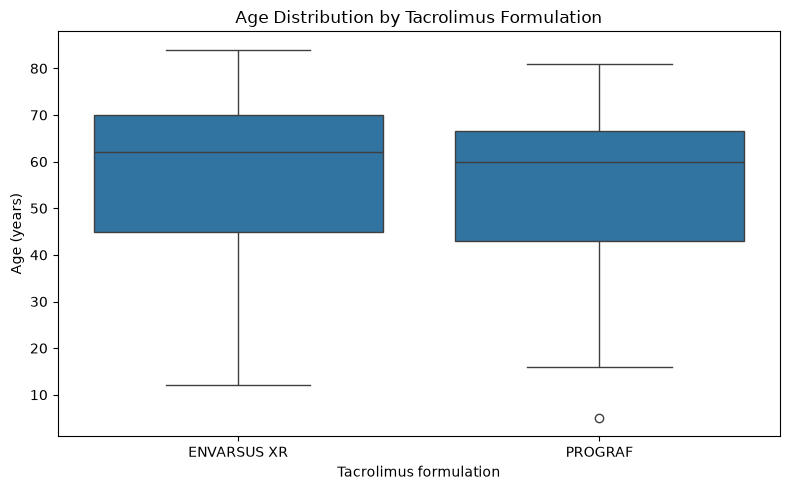

In [28]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.10. Plot: age by formulation
# -------------------------------------------------------------

# 1. Boxplot of age by formulation
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_analysis, x="formulation", y="age_years")

# 2. Labels and title
plt.xlabel("Tacrolimus formulation")
plt.ylabel("Age (years)")
plt.title("Age Distribution by Tacrolimus Formulation")
plt.tight_layout()

# 3. Save and show
plt.savefig(plots_dir / "02_age_by_formulation.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.11. Sex by formulation (counts)
# -------------------------------------------------------------

# The 18 reports without sex information are not included in this table

sex_table = pd.crosstab(df_analysis["formulation"], df_analysis["sex"])

print(sex_table)

sex          Female  Male
formulation              
ENVARSUS XR      54    44
PROGRAF          28    29


In [30]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.12. Sex by formulation (percentages)
# -------------------------------------------------------------

# 1. Row percentages among reports with known sex
sex_percent = pd.crosstab(df_analysis["formulation"], df_analysis["sex"], normalize="index") * 100

print(sex_percent.round(2))

sex          Female   Male
formulation               
ENVARSUS XR   55.10  44.90
PROGRAF       49.12  50.88


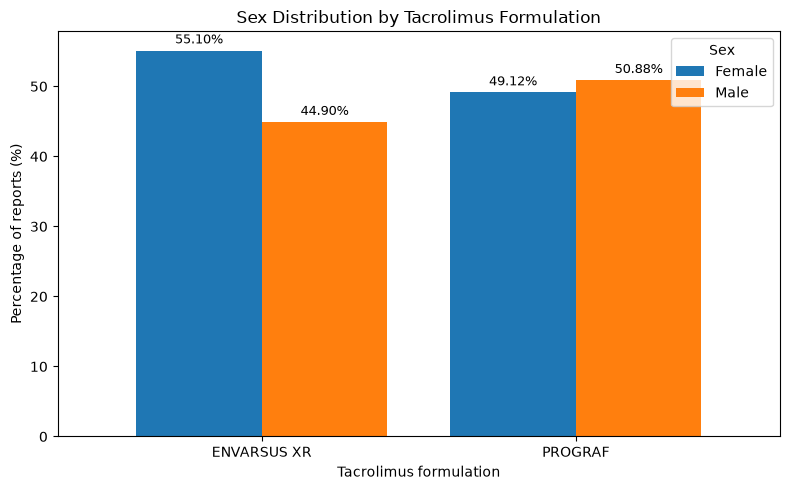

In [31]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.13. Plot: sex by formulation
# -------------------------------------------------------------

# 1. Grouped bar chart
ax = sex_percent.plot(kind="bar", figsize=(8, 5), width=0.8)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=9)

# 2. Labels and title
plt.xlabel("Tacrolimus formulation")
plt.ylabel("Percentage of reports (%)")
plt.title("Sex Distribution by Tacrolimus Formulation")
plt.xticks(rotation=0)
plt.legend(title="Sex")
plt.tight_layout()

# 3. Save and show
plt.savefig(plots_dir / "03_sex_by_formulation.png", dpi=300, bbox_inches="tight")
plt.show()

### Demographic characterization

| Variable | Envarsus XR | Prograf |
|---|---|---|
| Reports with known age | 73 of 111 | 55 of 62 |
| Age, mean (SD) | 56.56 (17.73) | 53.42 (18.25) |
| Age, median (min–max) | 62.0 (12–84) | 60.0 (5–81) |
| Reports with known sex | 98 of 111 | 57 of 62 |
| Female | 54 (55.10%) | 28 (49.12%) |
| Male | 44 (44.90%) | 29 (50.88%) |

Overall, the mean age was 55.21 years (median 60). Sex percentages are calculated among reports with known sex. These are descriptive comparisons; no statistical tests were applied to demographic variables.

In [32]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.14. Add serious outcome fields
# -------------------------------------------------------------

# 1. Serious outcome columns
outcome_columns = [
    "safetyreportid",
    "seriousnessdeath",
    "seriousnesshospitalization",
    "seriousnessdisabling",
    "seriousnesslifethreatening",
    "seriousnesscongenitalanomali",  # spelled this way in openFDA
    "seriousnessother"
]

# 2. Select those columns
df_outcomes = df_candidates[outcome_columns].copy()

# 3. Add them to the analysis DataFrame
df_analysis = pd.merge(df_analysis, df_outcomes, on="safetyreportid", how="left")

# 4. Show results
print("Dimensions:", df_analysis.shape)
print(df_analysis[outcome_columns[1:]].head().to_string(index=False))

Dimensions: (173, 17)
seriousnessdeath seriousnesshospitalization seriousnessdisabling seriousnesslifethreatening seriousnesscongenitalanomali seriousnessother
             NaN                        NaN                    1                        NaN                          NaN              NaN
               2                          1                    2                          2                            2                2
               2                          2                    2                          2                            2                1
               2                          2                    1                          2                            2                2
               2                          1                    2                          2                            2                2


In [33]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.15. Function: summarize a serious outcome by formulation
# -------------------------------------------------------------

def summarize_outcome(column, outcome_name):
    """Count reports with a serious outcome and their percentage by formulation."""

    # 1. Group by formulation: all reports (size) and reports with the outcome (== "1")
    summary = df_analysis.groupby("formulation").agg(
        total_reports=(column, "size"),
        reports_with_outcome=(column, lambda x: (x == "1").sum())
    ).reset_index()

    # 2. Percentage of reports with the outcome
    summary["percentage"] = (summary["reports_with_outcome"] / summary["total_reports"]) * 100

    # 3. Outcome label
    summary["outcome"] = outcome_name

    return summary

In [34]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.16. Serious outcomes by formulation
# -------------------------------------------------------------

# 1. Apply the function to each outcome
hospitalization_table    = summarize_outcome("seriousnesshospitalization", "Hospitalization")
death_table              = summarize_outcome("seriousnessdeath", "Death")
disability_table         = summarize_outcome("seriousnessdisabling", "Disability")
life_threatening_table   = summarize_outcome("seriousnesslifethreatening", "Life-threatening")
congenital_anomaly_table = summarize_outcome("seriousnesscongenitalanomali", "Congenital anomaly")
other_events_table       = summarize_outcome("seriousnessother", "Other medically important events")

# 2. Combine the six outcomes
outcomes_comparison = pd.concat(
    [
        hospitalization_table,
        death_table,
        disability_table,
        life_threatening_table,
        congenital_anomaly_table,
        other_events_table
    ],
    ignore_index=True
)

# 3. Order columns and rows
outcomes_comparison = outcomes_comparison[["formulation", "outcome", "total_reports", "reports_with_outcome", "percentage"]]
outcomes_comparison = outcomes_comparison.sort_values(["outcome", "formulation"]).reset_index(drop=True)

# 4. Show the final table
print(outcomes_comparison.round(2).to_string(index=False))

formulation                          outcome  total_reports  reports_with_outcome  percentage
ENVARSUS XR               Congenital anomaly            111                     0        0.00
    PROGRAF               Congenital anomaly             62                     0        0.00
ENVARSUS XR                            Death            111                    26       23.42
    PROGRAF                            Death             62                     7       11.29
ENVARSUS XR                       Disability            111                     6        5.41
    PROGRAF                       Disability             62                     3        4.84
ENVARSUS XR                  Hospitalization            111                    58       52.25
    PROGRAF                  Hospitalization             62                    27       43.55
ENVARSUS XR                 Life-threatening            111                     2        1.80
    PROGRAF                 Life-threatening             62 

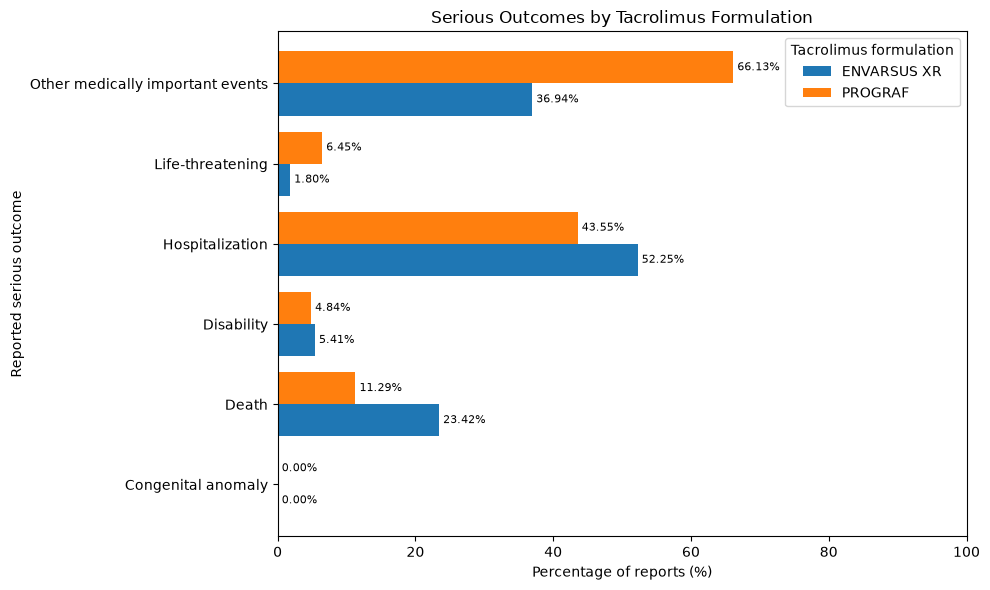

In [35]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.17. Plot: serious outcomes by formulation
# -------------------------------------------------------------

# 1. Reshape: one row per outcome, one column per formulation
outcomes_percentage = outcomes_comparison.pivot(index="outcome", columns="formulation", values="percentage")

# 2. Grouped horizontal bar chart
ax = outcomes_percentage.plot(kind="barh", figsize=(10, 6), width=0.8)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=8)

# 3. Labels and title
plt.xlabel("Percentage of reports (%)")
plt.ylabel("Reported serious outcome")
plt.title("Serious Outcomes by Tacrolimus Formulation")
plt.xlim(0, 100)
plt.legend(title="Tacrolimus formulation")
plt.tight_layout()

# 4. Save and show
plt.savefig(plots_dir / "04_serious_outcomes_by_formulation.png", dpi=300, bbox_inches="tight")
plt.show()

### Serious outcomes: Envarsus XR vs. Prograf

| Outcome | Envarsus XR (n = 111) | Prograf (n = 62) |
|---|---|---|
| Death | 26 (23.42%) | 7 (11.29%) |
| Hospitalization | 58 (52.25%) | 27 (43.55%) |
| Disability | 6 (5.41%) | 3 (4.84%) |
| Life-threatening | 2 (1.80%) | 4 (6.45%) |
| Other medically important events | 41 (36.94%) | 41 (66.13%) |
| Congenital anomaly | 0 (0.00%) | 0 (0.00%) |

Hospitalization was the most frequent serious outcome in Envarsus XR reports (52.25%), whereas in Prograf reports the most frequent was "Other medically important events" (66.13%), followed by hospitalization (43.55%). The proportion of reports with death was higher for Envarsus XR (23.42%) than for Prograf (11.29%). Disability and life-threatening outcomes appeared in few reports (2 to 6 per formulation), so their percentages are unstable. No congenital anomalies were reported.

A report can include more than one serious outcome, so percentages do not add up to 100%. These differences are descriptive: they were not tested statistically and do not support conclusions about the comparative safety of the formulations.

**Methodological note:** the denominator (`total_reports`) is the number of unique reports (`safetyreportid`) for each formulation: **111** for Envarsus XR and **62** for Prograf (N = 173). According to the [openFDA documentation](https://open.fda.gov/apis/drug/event/searchable-fields/), the serious outcome fields (`seriousness*`) are recorded only when the criterion applies and are omitted otherwise. Therefore, a missing field was interpreted as the outcome not having occurred, and only the value `"1"` was counted as an occurrence (some reports also contain the value `"2"`, which was likewise treated as not occurred). Percentages describe the proportion of reports with each outcome within the cohort and do not represent incidence or risk.

In [36]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.18. Explore the structure of reactions
# -------------------------------------------------------------

# 1. Inspect one report's reactions
reaction_sample = df_candidates["patient.reaction"].dropna().iloc[0]

# 2. Show its content and data type (a list of dictionaries)
print(reaction_sample)
print(type(reaction_sample))

[{'reactionmeddraversionpt': '28.0', 'reactionmeddrapt': 'Systemic lupus erythematosus', 'reactionoutcome': '3'}]
<class 'list'>


In [37]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.19. One row per reaction
# -------------------------------------------------------------

# 1. Expand the list of reactions of each report
df_reactions = df_candidates[["safetyreportid", "patient.reaction"]].explode("patient.reaction").copy()

# 2. Drop rows without reaction information
df_reactions = df_reactions.loc[df_reactions["patient.reaction"].notna()].copy()

# 3. Show results
print(df_reactions.head().to_string(index=False))
print("\nShape:", df_reactions.shape)

safetyreportid                                                                                                     patient.reaction
      24864132      {'reactionmeddraversionpt': '28.0', 'reactionmeddrapt': 'Systemic lupus erythematosus', 'reactionoutcome': '3'}
      25679307 {'reactionmeddraversionpt': '29.0', 'reactionmeddrapt': 'Acute myeloid leukaemia recurrent', 'reactionoutcome': '1'}
      25679307 {'reactionmeddraversionpt': '29.0', 'reactionmeddrapt': 'Graft versus host disease in skin', 'reactionoutcome': '1'}
      25679307                  {'reactionmeddraversionpt': '29.0', 'reactionmeddrapt': 'Renal impairment', 'reactionoutcome': '2'}
      25679307                    {'reactionmeddraversionpt': '29.0', 'reactionmeddrapt': 'Liver disorder', 'reactionoutcome': '1'}

Shape: (3911, 2)


In [38]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.20. Normalize reaction fields
# -------------------------------------------------------------

# 1. Expand each reaction dictionary into columns
reaction_details = pd.json_normalize(df_reactions["patient.reaction"])

# 2. Combine the report identifier with the reaction fields
df_reactions = pd.concat(
    [df_reactions[["safetyreportid"]].reset_index(drop=True), reaction_details.reset_index(drop=True)],
    axis=1
)

# 3. Show results
print(df_reactions.head().to_string(index=False))
print("\nShape:", df_reactions.shape)
print("\nColumns:", df_reactions.columns.tolist())

safetyreportid reactionmeddraversionpt                  reactionmeddrapt reactionoutcome
      24864132                    28.0      Systemic lupus erythematosus               3
      25679307                    29.0 Acute myeloid leukaemia recurrent               1
      25679307                    29.0 Graft versus host disease in skin               1
      25679307                    29.0                  Renal impairment               2
      25679307                    29.0                    Liver disorder               1

Shape: (3911, 4)

Columns: ['safetyreportid', 'reactionmeddraversionpt', 'reactionmeddrapt', 'reactionoutcome']


In [39]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.21. Reaction data quality
# -------------------------------------------------------------

print("Missing MedDRA terms:", df_reactions["reactionmeddrapt"].isna().sum())
print("Reports with reaction information:", df_reactions["safetyreportid"].nunique())
print("Distinct reaction terms:", df_reactions["reactionmeddrapt"].nunique())

Missing MedDRA terms: 0
Reports with reaction information: 1072
Distinct reaction terms: 1185


In [40]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.22. Identify duplicated reactions
# -------------------------------------------------------------

# 1. Repeated report-reaction combinations
duplicated_reactions = df_reactions.loc[
    df_reactions.duplicated(subset=["safetyreportid", "reactionmeddrapt"], keep=False)
].copy()

# 2. Rows involved
print("Rows in duplicated combinations:", len(duplicated_reactions))

# 3. Examples
print(duplicated_reactions.sort_values(["safetyreportid", "reactionmeddrapt"]).head(10).to_string(index=False))

Rows in duplicated combinations: 147
safetyreportid reactionmeddraversionpt                    reactionmeddrapt reactionoutcome
      24871891                    27.1                   Nephropathy toxic               6
      24871891                    27.1                   Nephropathy toxic               6
      24893378                    27.1 Haemophagocytic lymphohistiocytosis               5
      24893378                    27.1 Haemophagocytic lymphohistiocytosis               6
      24941792                    27.1                       Diabetic foot               6
      24941792                    27.1                       Diabetic foot               6
      24941792                    27.1                      Leg amputation               6
      24941792                    27.1                      Leg amputation               6
      24941792                    27.1                          Skin ulcer               6
      24941792                    27.1               

In [41]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.23. Remove duplicated reactions
# -------------------------------------------------------------

# 1. Keep one row per report-reaction combination
df_reactions_unique = df_reactions.drop_duplicates(subset=["safetyreportid", "reactionmeddrapt"]).copy()

# 2. Compare before and after
print("Original rows:", len(df_reactions))
print("Rows without duplicates:", len(df_reactions_unique))
print("Rows removed:", len(df_reactions) - len(df_reactions_unique))

Original rows: 3911
Rows without duplicates: 3824
Rows removed: 87


In [42]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.24. Add formulation to unique reactions
# -------------------------------------------------------------

# 1. Inner join keeps only reactions from cohort reports
df_reactions_unique = pd.merge(
    df_reactions_unique,
    df_analysis[["safetyreportid", "formulation"]],
    on="safetyreportid",
    how="inner"
)

# 2. Show results
print("Shape:", df_reactions_unique.shape)
print(df_reactions_unique["formulation"].value_counts())

Shape: (430, 5)
formulation
ENVARSUS XR    231
PROGRAF        199
Name: count, dtype: int64


In [43]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.25. Function: top 10 reactions by formulation
# -------------------------------------------------------------

def summarize_reaction(formulation):
    """Top 10 reactions (MedDRA Preferred Terms), including ties, with their percentage of reports."""

    # 1. Reactions of the formulation
    reactions = df_reactions_unique.loc[df_reactions_unique["formulation"] == formulation].copy()

    # 2. Unique reports per MedDRA term
    top_reactions = reactions.groupby("reactionmeddrapt").agg(
        total_reports=("safetyreportid", "nunique")
    ).reset_index()

    # 3. Rank over all reactions (ties share the same rank)
    top_reactions["rank"] = top_reactions["total_reports"].rank(method="min", ascending=False).astype(int)

    # 4. Keep the top 10 ranks, including ties
    top_reactions = top_reactions.loc[top_reactions["rank"] <= 10].sort_values("rank")

    # 5. Total reports of the formulation (denominator)
    total_formulation_reports = df_analysis.loc[df_analysis["formulation"] == formulation, "safetyreportid"].nunique()

    # 6. Percentage of reports
    top_reactions["percentage"] = (top_reactions["total_reports"] / total_formulation_reports) * 100

    return top_reactions

In [44]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.26. Top 10 reactions: Envarsus XR and Prograf
# -------------------------------------------------------------

envarsus_top_reactions = summarize_reaction("ENVARSUS XR")
prograf_top_reactions = summarize_reaction("PROGRAF")

print("ENVARSUS XR")
print(envarsus_top_reactions.round(2).to_string(index=False))

print("\nPROGRAF")
print(prograf_top_reactions.round(2).to_string(index=False))

ENVARSUS XR
                      reactionmeddrapt  total_reports  rank  percentage
                                 Death             20     1       18.02
               Urinary tract infection              7     2        6.31
                             Neuralgia              6     3        5.41
Immunosuppressant drug level increased              5     4        4.50
                             Pneumonia              5     4        4.50
                         Off label use              5     4        4.50
                             Diarrhoea              5     4        4.50
                             Dizziness              4     8        3.60
                              Dyspnoea              4     8        3.60
                                  Fall              3    10        2.70
                            Chest pain              3    10        2.70
            Blood creatinine increased              3    10        2.70
                             Infection              

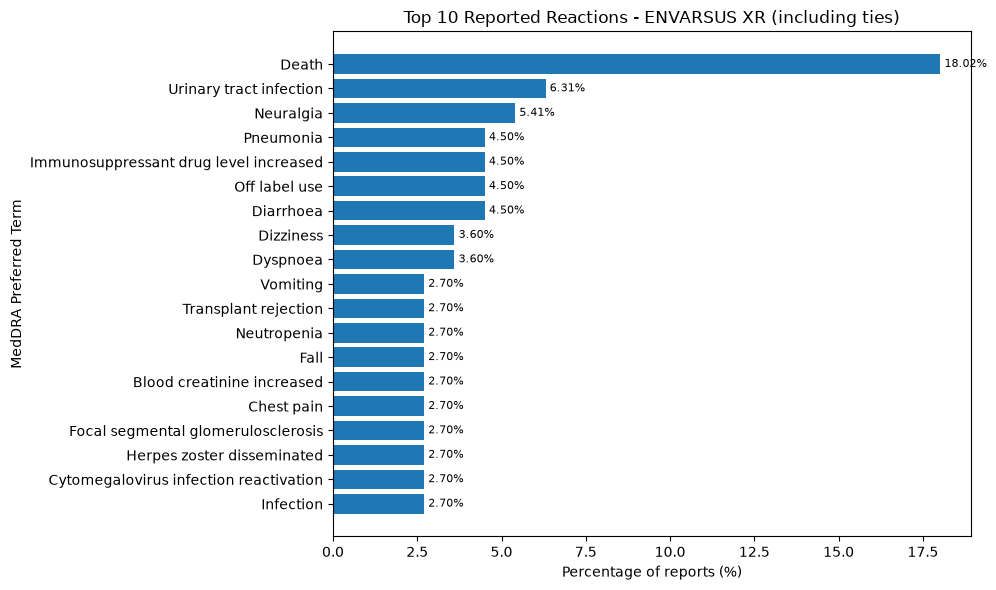

In [45]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.27. Plot: top 10 reactions, ENVARSUS XR
# -------------------------------------------------------------

# 1. Sort by percentage (ascending so the largest bar is on top)
envarsus_plot = envarsus_top_reactions.sort_values("percentage", ascending=True)

# 2. Horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(envarsus_plot["reactionmeddrapt"], envarsus_plot["percentage"])

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=8)

# 3. Labels and title
ax.set_xlabel("Percentage of reports (%)")
ax.set_ylabel("MedDRA Preferred Term")
ax.set_title("Top 10 Reported Reactions - ENVARSUS XR (including ties)")
plt.tight_layout()

# 4. Save and show
plt.savefig(plots_dir / "05_top_reactions_envarsus.png", dpi=300, bbox_inches="tight")
plt.show()

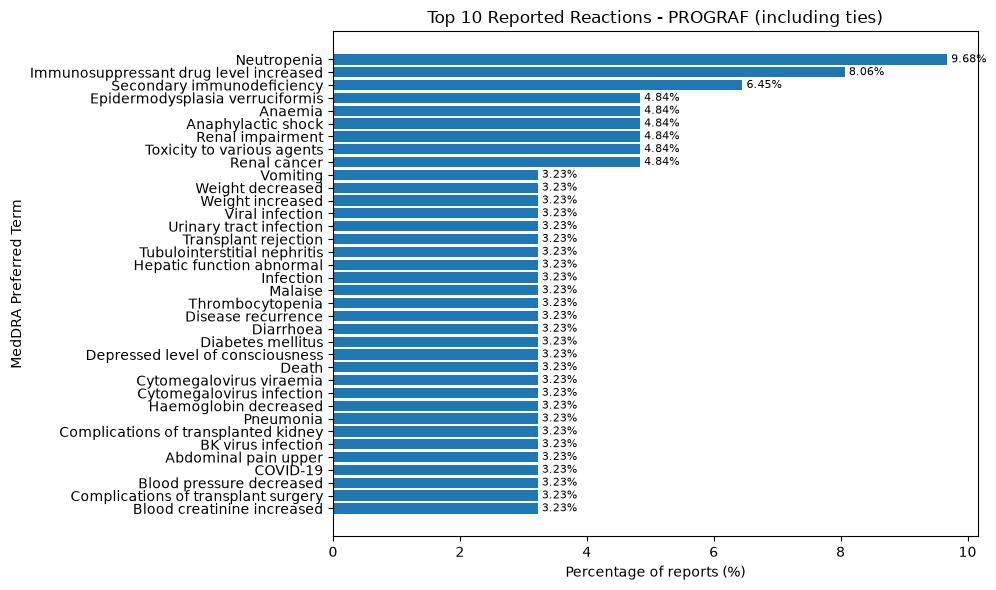

In [46]:
# -------------------------------------------------------------
# MODULE 3. DESCRIPTIVE ANALYSIS
# Step 3.28. Plot: top 10 reactions, PROGRAF
# -------------------------------------------------------------

# 1. Sort by percentage (ascending so the largest bar is on top)
prograf_plot = prograf_top_reactions.sort_values("percentage", ascending=True)

# 2. Horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(prograf_plot["reactionmeddrapt"], prograf_plot["percentage"])

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=8)

# 3. Labels and title
ax.set_xlabel("Percentage of reports (%)")
ax.set_ylabel("MedDRA Preferred Term")
ax.set_title("Top 10 Reported Reactions - PROGRAF (including ties)")
plt.tight_layout()

# 4. Save and show
plt.savefig(plots_dir / "06_top_reactions_prograf.png", dpi=300, bbox_inches="tight")
plt.show()

### Most frequently reported reactions (MedDRA Preferred Terms)

The tables above show the ten most frequent MedDRA Preferred Terms (PTs) for each formulation, ranked by the number of unique reports. Tied terms share the same rank, so a top 10 can contain more than ten rows. A report can include several PTs, so percentages are not additive.

**Envarsus XR (n = 111).** The most frequent term was *Death*, present in 20 of 111 reports (18.02%), followed by *Urinary tract infection* (7; 6.31%) and *Neuralgia* (6; 5.41%). Four terms tied for fourth place with 5 reports each (4.50%): *Immunosuppressant drug level increased*, *Pneumonia*, *Off label use*, and *Diarrhoea*. Several terms in the top 10 correspond to infections (*Urinary tract infection*, *Pneumonia*, *Infection*, *Herpes zoster disseminated*, and *Cytomegalovirus infection reactivation*).

**Prograf (n = 62).** The most frequent term was *Neutropenia*, present in 6 of 62 reports (9.68%), followed by *Immunosuppressant drug level increased* (5; 8.06%) and *Secondary immunodeficiency* (4; 6.45%). Six terms tied for fourth place with 3 reports each (4.84%): *Anaemia*, *Epidermodysplasia verruciformis*, *Anaphylactic shock*, *Renal impairment*, *Toxicity to various agents*, and *Renal cancer*. Several terms correspond to haematological and immunological disorders (*Neutropenia*, *Secondary immunodeficiency*, *Anaemia*), while several infections tied for tenth place with 2 reports each (*BK virus infection*, *COVID-19*, *Cytomegalovirus viraemia*, *Cytomegalovirus infection*, *Pneumonia*, *Infection*, *Urinary tract infection*, and *Viral infection*).

**Note on *Death*:** in FAERS, the PT *Death* is often used to record the outcome when the reporter did not specify a cause, so it should not be interpreted as a specific adverse reaction.

## Module 4. Statistical analysis

In Module 3, 93.69% of Envarsus XR reports were serious (104/111), compared with 98.39% of Prograf reports (61/62), a difference of 4.70 percentage points. This module evaluates whether the data provide statistical evidence of an association between formulation and report seriousness.

The comparison is similar to an A/B test of two proportions (A: Envarsus XR, B: Prograf). Because the Non-serious group is very small, an exact test is used and the association is summarized with an odds ratio and its exact 95% confidence interval.

In [47]:
# -------------------------------------------------------------
# MODULE 4. STATISTICAL ANALYSIS
# Step 4.1. Contingency table
# -------------------------------------------------------------

# 1. Formulation vs. seriousness
contingency_table = pd.crosstab(df_analysis["formulation"], df_analysis["seriousness"])

print(contingency_table.to_string())

seriousness  Non-serious  Serious
formulation                      
ENVARSUS XR            7      104
PROGRAF                1       61


In [48]:
# -------------------------------------------------------------
# MODULE 4. STATISTICAL ANALYSIS
# Step 4.2. Expected frequencies (Cochran's rule)
# -------------------------------------------------------------

# Cochran's rule for a 2 x 2 table: the chi-square approximation is appropriate when
# no expected frequency is below 1 and no more than 20% of cells have expected frequencies below 5.
# If either condition fails, Fisher's exact test is more appropriate.

# 1. Expected frequencies (chi2_stat is also used later to compute Phi)
chi2_stat, p_value_chi2, dof, expected_freq = scipy.stats.chi2_contingency(
    contingency_table,
    correction=False
)

# 2. Convert to a DataFrame
expected_table = pd.DataFrame(
    expected_freq,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("Expected frequencies:")
print(expected_table.round(2).to_string())

Expected frequencies:
seriousness  Non-serious  Serious
formulation                      
ENVARSUS XR         5.13   105.87
PROGRAF             2.87    59.13


In [49]:
# -------------------------------------------------------------
# MODULE 4. STATISTICAL ANALYSIS
# Step 4.3. Fisher's exact test
# -------------------------------------------------------------

# One of four cells (25%) has an expected frequency below 5 (2.87), so Fisher's exact test is used

# 1. Two-sided test (association in either direction)
odds_ratio, p_value_fisher = scipy.stats.fisher_exact(
    contingency_table,
    alternative="two-sided"
)

# 2. Show results
print("Sample odds ratio:", odds_ratio)
print("P-value:", p_value_fisher)

Sample odds ratio: 4.105769230769231
P-value: 0.2615174871298745


### Fisher's exact test: interpretation

**What is being calculated?**

- **Odds ratio (OR):** quantifies the association between formulation and report seriousness, following the table's orientation (Envarsus XR in row 1, Non-serious in column 1).
- **P-value:** assesses how compatible the observed data are with the null hypothesis. A two-sided test was used to evaluate an association in either direction, without specifying a direction in advance.

**Hypotheses**

- H₀: there is no association between formulation and report seriousness.
- H₁: there is an association between formulation and report seriousness.

**Results**

- **P-value = 0.2615 (> 0.05).** The null hypothesis is not rejected: the data do not provide sufficient statistical evidence of an association between formulation and report seriousness in this sample.
- **Sample OR = 4.11.** The odds of a report being Non-serious were 4.11 times higher for Envarsus XR than for Prograf. This value is not statistically significant and should not be interpreted as evidence that one formulation is safer than the other. The next step estimates the OR with its 95% confidence interval.
- **Sample size.** There were only 8 Non-serious reports in total (7 for Envarsus XR and 1 for Prograf). With so few cases, the analysis has low statistical power and the OR is very unstable: one more or one fewer Non-serious Prograf report would change the result substantially.

In [50]:
# -------------------------------------------------------------
# MODULE 4. STATISTICAL ANALYSIS
# Step 4.4. Conditional odds ratio and exact 95% CI
# -------------------------------------------------------------

# The confidence interval shows the precision of the estimate.
# If it includes 1, the data are compatible with no association.

# 1. Conditional maximum likelihood OR (same method as Fisher's exact test)
or_result = scipy.stats.contingency.odds_ratio(contingency_table, kind="conditional")

# 2. Exact 95% confidence interval
or_ci = or_result.confidence_interval(confidence_level=0.95)

# 3. Show results
print("Odds ratio (Non-serious):", or_result.statistic)
print("95% CI lower:", or_ci.low)
print("95% CI upper:", or_ci.high)

Odds ratio (Non-serious): 4.080355743419553
95% CI lower: 0.5046619077500257
95% CI upper: 188.02360485273286


The conditional OR (4.08) differs slightly from the sample OR reported by Fisher's exact test (4.11) because it is estimated by conditional maximum likelihood, the same approach underlying Fisher's exact test. Its confidence interval is exact, which is more appropriate when some cells have small counts, as in this table (1 Non-serious Prograf report).

In [51]:
# -------------------------------------------------------------
# MODULE 4. STATISTICAL ANALYSIS
# Step 4.5. Invert the OR to describe Serious reports
# -------------------------------------------------------------

# The outcome of interest is "Serious", so the OR is inverted (1 / OR)
# and the confidence limits are swapped.

# 1. Invert the point estimate and the CI limits
or_serious = 1 / or_result.statistic
ic_low_serious = 1 / or_ci.high   # the original upper limit becomes the lower limit
ic_high_serious = 1 / or_ci.low   # the original lower limit becomes the upper limit

# 2. Show results
print(f"OR (Serious): {or_serious:.4f}")
print(f"95% CI lower: {ic_low_serious:.4f}")
print(f"95% CI upper: {ic_high_serious:.4f}")

OR (Serious): 0.2451
95% CI lower: 0.0053
95% CI upper: 1.9815


### Odds ratio (Serious): interpretation

Because the outcome of interest is a **Serious** report, the conditional OR was inverted (1 / 4.08) and its confidence limits were swapped. The OR therefore describes the odds of a report being Serious for Envarsus XR compared with Prograf.

**How to read an OR**

- **OR = 1:** the odds of a Serious report are the same for both formulations.
- **OR < 1:** the odds of a Serious report are lower for Envarsus XR than for Prograf.
- **OR > 1:** the odds of a Serious report are higher for Envarsus XR than for Prograf.

**Results**

- **OR (Serious) = 0.25.** The point estimate indicates lower odds of a Serious report for Envarsus XR than for Prograf.
- **95% CI = 0.0053 to 1.9815.** The interval is very wide and includes 1: the data are compatible with much lower odds as well as with nearly twofold higher odds for Envarsus XR. This reflects substantial uncertainty in the estimate.
- **Fisher p = 0.2615.** There was no statistically significant evidence of an association between formulation and report seriousness.

**Methodological consideration:** there were only 8 Non-serious reports (7 for Envarsus XR and 1 for Prograf). This highly unbalanced distribution explains the width of the interval.

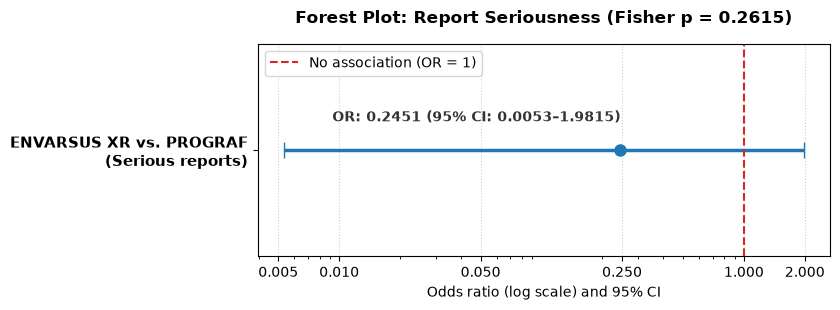

In [52]:
# -------------------------------------------------------------
# MODULE 4. STATISTICAL ANALYSIS
# Step 4.6. Plot: forest plot of the OR (Serious)
# -------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.5, 3.2))

# 1. Point estimate and 95% CI
ax.errorbar(
    x=or_serious,
    y=0,
    xerr=[[or_serious - ic_low_serious], [ic_high_serious - or_serious]],
    fmt="o",
    color="#1f77b4",
    ecolor="#1f77b4",
    elinewidth=2.5,
    capsize=6,
    markersize=8
)

# 2. Reference line at OR = 1 (no association)
ax.axvline(x=1, color="#d62728", linestyle="--", linewidth=1.5, label="No association (OR = 1)")

# 3. Log scale: ratios are symmetric around 1 (0.5 and 2 are equally distant from 1)
ax.set_xscale("log")
ax.set_xticks([0.005, 0.01, 0.05, 0.25, 1, 2])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())

# 4. Labels and title
ax.set_yticks([0])
ax.set_yticklabels(["ENVARSUS XR vs. PROGRAF\n(Serious reports)"], fontsize=11, fontweight="bold")
ax.set_xlabel("Odds ratio (log scale) and 95% CI", fontsize=10)
ax.set_title(f"Forest Plot: Report Seriousness (Fisher p = {p_value_fisher:.4f})", fontsize=12, fontweight="bold", pad=15)

# 5. Annotation with the OR and its CI
ax.text(
    or_serious, 0.12,
    f"OR: {or_serious:.4f} (95% CI: {ic_low_serious:.4f}–{ic_high_serious:.4f})",
    ha="right", va="bottom", fontsize=10, fontweight="bold", color="#333333"
)

ax.set_ylim(-0.5, 0.5)
ax.grid(axis="x", linestyle=":", alpha=0.6)
ax.legend(loc="upper left")
plt.tight_layout()

# 6. Save and show
plt.savefig(plots_dir / "07_forest_plot_or_serious.png", dpi=300, bbox_inches="tight")
plt.show()

### Forest plot: interpretation

The point shows the estimated OR (0.25) and the horizontal line its 95% confidence interval (0.0053 to 1.9815). The dashed vertical line marks OR = 1, where the odds of a Serious report would be the same for both formulations.

A log scale is used because ORs are ratios: on this scale, an OR of 0.5 and an OR of 2 are the same distance from 1.

The interval crosses OR = 1, consistent with the non-significant result of Fisher's exact test (p = 0.2615). Its width, spanning almost three orders of magnitude, shows the large uncertainty of the estimate, a consequence of the small number of Non-serious reports.

In [53]:
# -------------------------------------------------------------
# MODULE 4. STATISTICAL ANALYSIS
# Step 4.7. Phi coefficient (reference only)
# -------------------------------------------------------------

# Although the chi-square p-value is not used for hypothesis testing (Step 4.2),
# its statistic (chi2_stat) is the standard basis for computing Phi.
# Computed as the square root of chi2 / n, Phi ranges from 0 to 1.

# 1. Total observations and Phi
n = contingency_table.to_numpy().sum()
phi = np.sqrt(chi2_stat / n)

print(f"Phi coefficient: {phi:.4f}")

Phi coefficient: 0.1072


### Phi coefficient

The Phi coefficient was 0.1072. Phi is reported for reference only: its maximum possible value is limited by the unbalanced margins of the table (8 Non-serious vs. 165 Serious reports), so here it cannot exceed approximately 0.29 and should not be interpreted with the usual magnitude thresholds. The interpretation of the analysis is based on the OR and its 95% CI.

In [54]:
# -------------------------------------------------------------
# MODULE 4. STATISTICAL ANALYSIS
# Step 4.8. Statistical analysis summary
# -------------------------------------------------------------

print("Statistical analysis summary")
print("----------------------------")
print("Total reports:", n)
print("Fisher's exact p-value:", round(p_value_fisher, 4))
print("Odds ratio (Serious):", round(or_serious, 4))
print("95% CI (Serious):", round(ic_low_serious, 4), "-", round(ic_high_serious, 4))
print("Phi coefficient:", round(phi, 4))

Statistical analysis summary
----------------------------
Total reports: 173
Fisher's exact p-value: 0.2615
Odds ratio (Serious): 0.2451
95% CI (Serious): 0.0053 - 1.9815
Phi coefficient: 0.1072


### Statistical analysis summary

| Measure | Value |
|---|---|
| Total reports | 173 (Envarsus XR: 111; Prograf: 62) |
| Fisher's exact test (two-sided) | p = 0.2615 |
| Odds ratio (Serious, Envarsus XR vs. Prograf) | 0.25 |
| 95% CI (exact, conditional) | 0.0053–1.9815 |
| Phi coefficient (reference only) | 0.1072 |

No statistically significant association was found between formulation and report seriousness. The full interpretation is presented in the conclusion below.

## Conclusion

### Pharmacovigilance perspective (the clinical question)

- **Question:** Does the proportion of serious reports differ between Envarsus XR and Prograf in 2025 FAERS reports for renal transplant patients?
- **Finding:** Almost all reports were serious for both formulations: 93.69% for Envarsus XR (104/111) and 98.39% for Prograf (61/62). The data show no statistically significant difference between them.

### Statistical perspective (the evidence behind it)

- **Fisher's exact test (p = 0.2615).** Chosen instead of chi-square because 25% of the cells had expected frequencies below 5 (only 1 Non-serious Prograf report). Since p > 0.05, the null hypothesis of no association is not rejected.
- **OR (Serious) = 0.25; 95% CI: 0.0053–1.9815.** The point estimate suggests lower odds of serious reports for Envarsus XR, but the interval is very wide and includes 1: the data are compatible with much lower odds as well as with nearly twofold higher odds.
- **Phi = 0.1072.** Reported for reference only; because of the unbalanced margins its maximum possible value is approximately 0.29, so the interpretation is based on the OR and its 95% CI.

### Interpretation

No statistically significant evidence of a difference in the proportion of serious reports between Envarsus XR and Prograf was found. However, a non-significant result does not show that the formulations are equivalent: with only 8 Non-serious reports, the analysis has low statistical power to distinguish a difference from its absence.

These results describe the FAERS reports analyzed. Because FAERS does not include the number of exposed patients, they cannot be used to estimate incidence or risk, establish causality, or compare the clinical safety of the formulations.

## Module 5. Export results

In [55]:
# -------------------------------------------------------------
# MODULE 5. EXPORT RESULTS
# Step 5.1. Export tables to CSV
# -------------------------------------------------------------

# 1. Tables indexed by formulation (crosstab and groupby): keep the index
seriousness_table.to_csv(tables_dir / "01_seriousness_counts.csv")
seriousness_percent.to_csv(tables_dir / "02_seriousness_percent.csv")
age_by_formulation.round(2).to_csv(tables_dir / "03_age_by_formulation.csv")
sex_percent.round(2).to_csv(tables_dir / "04_sex_percent.csv")

# 2. Tables with a numeric index: drop it
outcomes_comparison.round(2).to_csv(tables_dir / "05_serious_outcomes.csv", index=False)
envarsus_top_reactions.round(2).to_csv(tables_dir / "06_top_reactions_envarsus.csv", index=False)
prograf_top_reactions.round(2).to_csv(tables_dir / "07_top_reactions_prograf.csv", index=False)

# 3. Statistical summary as a table
stats_summary = pd.DataFrame({
    "measure": ["total_reports", "fisher_p_value", "or_serious", "ci95_low", "ci95_high", "phi"],
    "value": [n, p_value_fisher, or_serious, ic_low_serious, ic_high_serious, phi]
})
stats_summary.round(4).to_csv(tables_dir / "08_statistical_summary.csv", index=False)

# 4. List exported files
print("Exported tables:")
for file in sorted(tables_dir.glob("*.csv")):
    print(" -", file.name)

Exported tables:
 - 01_seriousness_counts.csv
 - 02_seriousness_percent.csv
 - 03_age_by_formulation.csv
 - 04_sex_percent.csv
 - 05_serious_outcomes.csv
 - 06_top_reactions_envarsus.csv
 - 07_top_reactions_prograf.csv
 - 08_statistical_summary.csv
